# KITScenes — Training with PyTorch

`kitscenes.SampleDataset` turns frames into dicts of numpy arrays (a *sample*), and `kitscenes.collate` batches them
for a `torch.utils.data.DataLoader`. `kitscenes.SampleSpec` says what a sample holds: cameras, lidars, radars, ego
past and future, clips of several frames, map labels. Workers only read and decode; the dataset pickles to scene IDs
and frame indices, so it works with any number of workers.

**Needs:** `kitscenes[torch,map,viz]` installed as in the README (torch from pytorch.org for your CUDA if needed). Without torch,
`collate` gives numpy arrays. The example scene and how to download it alone: notebook 01.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import kitscenes

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path
SCENE_ID = "c34c778f-ad8c-0aa9-7e1a-c86a73f887c7"  # the example scene (notebook 01); any scene UUID on disk works

import time

import torch
from torch.utils.data import DataLoader

ds = kitscenes.open(DATASET_ROOT).filter(scene_ids=[SCENE_ID])  # without the filter: every scene on disk


def shapes(tree, indent=""):
    """Print the layout of a sample or batch."""
    for key, value in tree.items():
        if isinstance(value, dict):
            print(f"{indent}{key}:")
            shapes(value, indent + "  ")
        else:
            print(f"{indent}{key}: {tuple(value.shape) if hasattr(value, 'shape') else value!r}"[:110])

# lanelet2 notes on the routing graphs of the maps (SceneMap.routing_problems lists them): not shown here
import logging
import warnings

from kitscenes.map import MapProblemWarning

warnings.filterwarnings("ignore", category=MapProblemWarning)
logging.getLogger("kitscenes.map.scene_map").addFilter(lambda record: "routing graph" not in record.getMessage())

## 1. Frames, specs and samples

`ds.frames(require=...)` is the flat list of frames that have the given sensors (scenes are opened in threads).
`SampleDataset(ds, spec)` builds it from the spec; a sample is a dict of arrays:

In [2]:
spec = kitscenes.SampleSpec(cameras=("camera_ring_front",), reduce=4, lidars=("lidar_top",), radars=("radar_front",),
                            future_s=3.0, past_s=1.0)
samples = kitscenes.SampleDataset(ds, spec)
print(samples)
shapes(samples[0])

SampleDataset(frames=220, spec=SampleSpec(cameras=('camera_ring_front',), image='decoded', reduce=4, lidars=('lidar_top',), lidar='deskewed', radars=('radar_front',), future_s=3.0, past_s=1.0, trajectory_step_s=0.1, map_labels=None, clip_length=1, clip_stride=1, require=True, frame='base', sd_map=None, navigation=None, image_correction=True))


meta:
  scene: 'c34c778f-ad8c-0aa9-7e1a-c86a73f887c7'
  split: 'val'
  index: 0
  token: 'c34c778f-ad8c-0aa9-7e1a-c86a73f887c7_0000'
  t_ns: 51987968
  pose_frame: 'local_utm'
  frame: 'base'
pose:
  T_world_base: (4, 4)
camera:
  camera_ring_front:
    image: (568, 876, 3)
    K: (3, 3)
    T_cam_base: (4, 4)
    valid: True
lidar:
  xyz: (208157, 3)
  reflectivity: (208157,)
  source: (208157,)
radar:
  xyz: (556, 3)
  range_rate: (556,)
  rcs: (556,)
  source: (556,)
ego:
  velocity: (3,)
  acceleration: (3,)
  yaw_rate: ()
  speed: ()
  valid: False
past:
  xyz_ego: (10, 3)
  quat_ego: (10, 4)
  valid: (10,)
future:
  xyz_ego: (30, 3)
  quat_ego: (30, 4)
  valid: (30,)
  command: ()
  command_valid: True


## 2. A DataLoader

`collate` stacks images and fixed-size arrays and concatenates point clouds with a `batch` index per point. Images come
channels first, `(B, 3, H, W)` uint8 (a single sample has `(H, W, 3)`); most models want float.

In [3]:
loader = DataLoader(samples, batch_size=4, shuffle=True, num_workers=2, collate_fn=kitscenes.collate)
batch = next(iter(loader))
shapes(batch)

images = batch["camera"]["camera_ring_front"]["image"].float() / 255  # (B, 3, H, W)
points_per_sample = torch.bincount(batch["lidar"]["batch"])
print("\nimages", tuple(images.shape), "| lidar points per sample", points_per_sample.tolist())

meta:
  scene: ['c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', 'c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', 'c34c778f-ad8c-0aa9-
  split: ['val', 'val', 'val', 'val']
  index: [132, 93, 32, 173]
  token: ['c34c778f-ad8c-0aa9-7e1a-c86a73f887c7_0132', 'c34c778f-ad8c-0aa9-7e1a-c86a73f887c7_0093', 'c34c778f-
  t_ns: [13251987968, 9351987968, 3251987968, 17351987968]
  pose_frame: ['local_utm', 'local_utm', 'local_utm', 'local_utm']
  frame: ['base', 'base', 'base', 'base']
pose:
  T_world_base: (4, 4, 4)
camera:
  camera_ring_front:
    image: (4, 3, 568, 876)
    K: (4, 3, 3)
    T_cam_base: (4, 4, 4)
    valid: (4,)
lidar:
  xyz: (831712, 3)
  reflectivity: (831712,)
  source: (831712,)
  batch: (831712,)
radar:
  xyz: (2040, 3)
  range_rate: (2040,)
  rcs: (2040,)
  source: (2040,)
  batch: (2040,)
ego:
  velocity: (4, 3)
  acceleration: (4, 3)
  yaw_rate: (4,)
  speed: (4,)
  valid: (4,)
past:
  xyz_ego: (4, 10, 3)
  quat_ego: (4, 10, 4)
  valid: (4, 10)
future:
  xyz_ego: (4, 30, 3)
  quat_ego: (

`K` is scaled to the reduced image and `T_cam_base` maps base-frame points (the sample's frame) into the camera, so lidar points project into
the batch images directly:

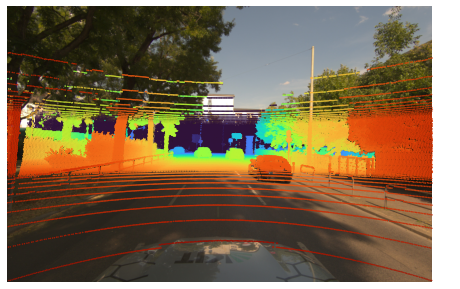

In [4]:
cam = batch["camera"]["camera_ring_front"]
b = 0
xyz = batch["lidar"]["xyz"][batch["lidar"]["batch"] == b].double()
p = (cam["T_cam_base"][b] @ torch.cat([xyz, torch.ones(len(xyz), 1, dtype=xyz.dtype)], 1).T)[:3]
front = p[2] > 1
uv = (cam["K"][b] @ p[:, front]) / p[2, front]
h, w = images.shape[2:]
inside = (uv[0] >= 0) & (uv[0] < w) & (uv[1] >= 0) & (uv[1] < h)
plt.figure(figsize=(8, 5.2))
plt.imshow(cam["image"][b].permute(1, 2, 0))  # (H, W, 3) for matplotlib
plt.scatter(uv[0, inside], uv[1, inside], s=0.2, c=p[2, front][inside], cmap="turbo_r", vmin=0, vmax=60)
plt.axis("off")
plt.show()

## 3. Ego past and future

`frame.future(horizon_s)` and `frame.past(horizon_s)` are the ego poses at fixed times (every `step_s`, 0.1 s by
default) after and before the frame, in the sample's frame (the base frame by default; `frame="road"` has the same x, y and heading) at the frame time: the usual planning target and history.
`valid` marks the slots the recorded poses cover (not past the end of the scene). In samples they are `future` and
`past` with `xyz_ego`, `quat_ego` and `valid`.

EgoTrajectory(index=110, anchor_t_ns=11051987968, t_ns=<int64 (30,)>, xyz_ego=<float64 (30, 3)>, quat_ego=<float64 (30, 4)>, xyz_world=<float64 (30, 3)>, valid=<bool (30,)>, frame='base', provenance='geometry_derived')


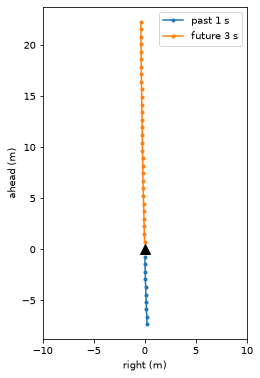

in the batch: (4, 30, 3) valid [True, True, True, True]


In [5]:
scene = ds[SCENE_ID]
frame = scene[len(scene) // 2]
future, past = frame.future(3.0), frame.past(1.0)
print(future)
fig, ax = plt.subplots(figsize=(4, 6))
ax.plot(-past.xyz_ego[:, 1], past.xyz_ego[:, 0], "o-", ms=3, label="past 1 s")
ax.plot(-future.xyz_ego[future.valid, 1], future.xyz_ego[future.valid, 0], "o-", ms=3, label="future 3 s")
ax.plot(0, 0, "k^", ms=10)
ax.set(xlim=(-10, 10), aspect="equal", xlabel="right (m)", ylabel="ahead (m)")
ax.legend()
plt.show()
print("in the batch:", tuple(batch["future"]["xyz_ego"].shape), "valid", batch["future"]["valid"].all(1).tolist())

## 4. Clips for temporal models

`SampleSpec(clip_length=N, clip_stride=s)` makes a sample a list of N frames of one scene (frames `i - (N-1)·s, …, i`,
the current one last). Each frame has `pose["T_last_base"]`, its base frame in the base frame of the current one.
`collate` returns one batch per clip position.

In [6]:
clip_spec = kitscenes.SampleSpec(cameras=("camera_ring_front",), reduce=8, clip_length=3, clip_stride=5)
clips = kitscenes.SampleDataset(ds, clip_spec)
clip_batch = kitscenes.collate([clips[len(clips) // 4], clips[3 * len(clips) // 4]])
print(clips, "->", len(clip_batch), "batches; frame indices per position:",
      [list(b["meta"]["index"]) for b in clip_batch])
video = torch.stack([b["camera"]["camera_ring_front"]["image"] for b in clip_batch], 1)  # (B, N, 3, H, W)
print("video", tuple(video.shape), "| oldest frame -> current frame:\n", clip_batch[0]["pose"]["T_last_base"][0].round(decimals=2))

SampleDataset(clips=210, spec=SampleSpec(cameras=('camera_ring_front',), image='decoded', reduce=8, lidars=(), lidar='deskewed', radars=(), future_s=0.0, past_s=0.0, trajectory_step_s=0.1, map_labels=None, clip_length=3, clip_stride=5, require=True, frame='base', sd_map=None, navigation=None, image_correction=True)) -> 3 batches; frame indices per position: [[52, 157], [57, 162], [62, 167]]
video (2, 3, 3, 284, 438) | oldest frame -> current frame:
 tensor([[ 1.0000, -0.0600, -0.0000, -8.1800],
        [ 0.0600,  1.0000, -0.0100, -0.4300],
        [ 0.0000,  0.0100,  1.0000,  0.0900],
        [ 0.0000,  0.0000,  0.0000,  1.0000]], dtype=torch.float64)


## 5. Map labels in samples

`SampleSpec(map_labels=kitscenes.MapLabelSpec(...))` adds the ML-converter labels around each frame (notebook 04).
Collated, each type's polylines are concatenated: `xyz` (P, 3), `length` per polyline and `batch` per polyline, the map
element `ids` behind each (`num_ids` per polyline), its `piece` of the chain and a `key` (int64, the same for the same
element in every frame with the same chain). Every type of the label set is there, empty where there is none.
`kitscenes.MapLabelSpec.maptr()` is the preset for MapTR-style models (classes `divider`, `ped_crossing`, `boundary`),
in the road frame of the map benchmark: it goes with `SampleSpec(frame="road")` (another frame raises `ValueError`).
Test splits have no maps: they raise `MapUnavailable`, or with `SampleSpec(require=False)` give samples whose
`map["state"]` says why.

In [7]:
from kitscenes.map import FixedPoints, Region

label_spec = kitscenes.MapLabelSpec(grouping="m3tr", region=Region(ahead=40, behind=20, left=20, right=20),
                                    sampling=FixedPoints(20))
map_samples = kitscenes.SampleDataset(ds, kitscenes.SampleSpec(lidars=("lidar_top",), map_labels=label_spec))
map_batch = kitscenes.collate([map_samples[40], map_samples[len(map_samples) - 40]])
print(map_batch["map"]["available"], map_batch["map"]["state"])
for name, poly in map_batch["map"]["lines"].items():
    print(f"{name:20s} {poly['length'].numel():3d} polylines, xyz {tuple(poly['xyz'].shape)}")
dashed = map_batch["map"]["lines"]["Dashed"]  # FixedPoints(20): every polyline has 20 points
print("Dashed as (L, 20, 3):", tuple(dashed["xyz"].reshape(-1, 20, 3).shape), "keys", dashed["key"][:3].tolist())

maptr_samples = kitscenes.SampleDataset(ds, kitscenes.SampleSpec(frame="road", map_labels=kitscenes.MapLabelSpec.maptr()))
maptr_batch = kitscenes.collate([maptr_samples[40], maptr_samples[len(maptr_samples) - 40]])
for name, poly in maptr_batch["map"]["lines"].items():
    print(f"maptr {name:12s} {tuple(poly['xyz'].reshape(-1, 20, 3).shape)}")

tensor([True, True]) ['present', 'present']
RoadBorder            20 polylines, xyz (400, 3)
Dashed                28 polylines, xyz (560, 3)
Solid                 20 polylines, xyz (400, 3)
Virtual               29 polylines, xyz (580, 3)
Centerline            16 polylines, xyz (320, 3)
BikeCenterline         5 polylines, xyz (100, 3)
Unknown                0 polylines, xyz (0, 3)
DrivableArea          11 polylines, xyz (220, 3)
PedestrianCrossing     5 polylines, xyz (100, 3)
Dashed as (L, 20, 3): (28, 20, 3) keys [3300587702469365032, -662870659663922916, 3787813240401139935]
maptr divider      (35, 20, 3)
maptr ped_crossing (7, 20, 3)
maptr boundary     (9, 20, 3)


## 6. Speed

- Workers: a `DataLoader` with `num_workers > 0` decodes in parallel; `reduce=` decodes JPEGs smaller, which is the
  biggest saving for images.
- `kitscenes.open(..., scene_cache=256)`: how many opened scenes (timeline, calibration, file index, map converter)
  a process keeps (default 32); raise it for a shuffled loader over many scenes, map labels above all.
- `kitscenes.open(..., cache_mb=1024)` keeps decoded payloads in memory (useful in notebooks, not in training).
- GPU decoding: `SampleSpec(image="bytes")` gives the JPEG bytes for `kitscenes.decode.decode_cameras` (section 7),
  and `SampleSpec(lidar="deskew_inputs")` the inputs of `kitscenes.motion_torch.deskew_on_device()`.

In [8]:
for workers in (0, 4):
    loader = DataLoader(samples, batch_size=4, shuffle=True, num_workers=workers, collate_fn=kitscenes.collate)
    t = time.perf_counter()
    for _, _ in zip(range(8), loader):
        pass
    print(f"num_workers={workers}: 8 batches of 4 in {time.perf_counter() - t:.1f} s (with the workers' start-up)")

num_workers=0: 8 batches of 4 in 2.4 s (with the workers' start-up)


num_workers=4: 8 batches of 4 in 1.2 s (with the workers' start-up)


## 7. Decoding on the GPU

The fastest input path: the workers only read the JPEG bytes (`SampleSpec(image="bytes")`), and the training loop
decodes each batch on the GPU at the model's input size with `kitscenes.decode.decode_cameras` (nvJPEG through
`torchvision.io.decode_jpeg`; needs torchvision). The samples carry the full-size JPEG and its full-size `K`;
`decode_cameras` resizes (to `1 / spec.reduce`, or any `size=(width, height)` / `scale=`) and scales `K` to match,
with the pixel-centre convention of `Camera.scaled`. The images come channels first, (B, 3, H, W), as from `collate`. Without CUDA or
torchvision this runs on the CPU (OpenCV or Pillow), which is only for trying it out.

bytes [1960968, 1625077, 1781775] ...
image (8, 3, 568, 876) torch.uint8 cpu
K matches Camera.scaled(1/4): True


800 x 520: (8, 3, 520, 800) K[0]:
 [[420.32   0.   396.87]
 [  0.   421.36 260.3 ]
 [  0.     0.     1.  ]]


37 images/s on cpu (decoding and resizing only)


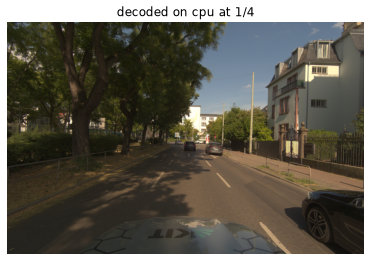

In [9]:
from kitscenes.decode import decode_cameras, decode_images

device = "cuda" if torch.cuda.is_available() else "cpu"
gpu_spec = kitscenes.SampleSpec(cameras=("camera_ring_front",), image="bytes", reduce=4)
gpu_loader = DataLoader(kitscenes.SampleDataset(ds, gpu_spec), batch_size=8, shuffle=True, num_workers=4,
                        collate_fn=kitscenes.collate)
raw = next(iter(gpu_loader))
batch = decode_cameras(raw, gpu_spec, device=device)
front = batch["camera"]["camera_ring_front"]
print("bytes", [len(b) for b in raw["camera"]["camera_ring_front"]["image"][:3]], "...")
print("image", tuple(front["image"].shape), front["image"].dtype, front["image"].device)
camera = ds.scene(raw["meta"]["scene"][0]).rig.cameras["camera_ring_front"]
print("K matches Camera.scaled(1/4):", np.allclose(front["K"][0].numpy(), camera.scaled(1 / 4).K))

# Any size, e.g. a model input of 800 x 520 (K scaled per axis), and the timing of one batch
sized = decode_cameras(raw, size=(800, 520), device=device)["camera"]["camera_ring_front"]
print("800 x 520:", tuple(sized["image"].shape), "K[0]:\n", sized["K"][0].numpy().round(2))
jpegs = raw["camera"]["camera_ring_front"]["image"]
decode_images(jpegs, scale=0.25, device=device)  # warm-up (nvJPEG start-up)
t = time.perf_counter()
for _ in range(5):
    decode_images(jpegs, scale=0.25, device=device)
if device == "cuda":
    torch.cuda.synchronize()
print(f"{5 * len(jpegs) / (time.perf_counter() - t):.0f} images/s on {device} (decoding and resizing only)")
plt.imshow(front["image"][0].permute(1, 2, 0).cpu())
plt.title("decoded on " + device + " at 1/4")
plt.axis("off");